# Galaxy morphology classifier: from a CSV catalog to a trained ML model

**Python Bootcamp 2026-27 · Exercises 1–5 merged into a single notebook**

Give it a **CSV catalog** and it runs the full workflow:

| Step | What happens |
|---|---|
| 1 | Load the CSV, build the morphology **class**; re-label uncertain galaxies with `p_cw + p_acw > 0.8` → spiral, `p_el > 0.8` → elliptical |
| 2 | Catalog overview figure (sky distribution + redshift) |
| 3 | Balanced sample of the classes to be learned |
| 4 | Download **64×64 SDSS cutouts** for each galaxy (cached, resumable) |
| 5 | Stamps → grayscale → 4096 pixel features |
| 6 | **PCA** (4096 → 64) + catalog features → single feature table |
| 7 | Train / evaluate an **SVC** (scikit-learn) + ablations, tuning, model comparison |
| 8 | Save the model, the predictions and all figures |

**How to use it:** put the name of your CSV in `CSV_PATH` (section 0) and run all cells.

**The CSV must contain:** `ra`, `dec` (degrees), the morphology (a `class` column or Galaxy Zoo flags `spiral` / `elliptical` / `uncertain`, 1 = true) and, for the re-labelling step, the vote fractions `p_cw`, `p_acw` and `p_el`. Any other numeric columns (redshift, magnitudes, sizes…) are used as extra features.

> ⚠️ Cutouts are downloaded from the SDSS SkyServer, so the notebook needs **internet access**.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn pillow requests tqdm joblib

## 0. Configuration

The only cell you normally need to edit.

In [2]:
from pathlib import Path

# ======================= INPUT =======================
CSV_PATH = Path("ZooSpecPhotoDR19_torradeflot.csv")   # <-- your catalog
OUTPUT_DIR = Path("outputs")                          # figures, cache, model, predictions

# ================= TARGET / CLASSES ==================
# Classes to learn. Order defines the label ids: first -> 0, second -> 1.
CLASSES = ["elliptical", "spiral"]
MAX_PER_CLASS = 25000          # galaxies per class (balanced sample). Use None for all.

# ========== RE-LABEL UNCERTAIN / UNKNOWN GALAXIES ==========
# Galaxies flagged "uncertain"/"unknown" are reassigned using the Galaxy Zoo
# vote fractions: spiral if the SUM of the P_SPIRAL_COLS (clockwise + anticlockwise)
# is > P_THRESHOLD, elliptical if P_ELLIPTICAL_COL > P_THRESHOLD.
# Galaxies already labelled spiral/elliptical keep their label.
RELABEL_UNCERTAIN = True
P_SPIRAL_COLS     = ["p_cw", "p_acw"]   # clockwise + anticlockwise spiral votes (lower-case names)
P_ELLIPTICAL_COL  = "p_el"    # vote fraction for elliptical
P_THRESHOLD       = 0.8

# ================= CUTOUT DOWNLOAD ===================
IMAGE_SIZE   = 64             # pixels (stamps are IMAGE_SIZE x IMAGE_SIZE)
SCALE        = 0.4            # arcsec / pixel
MAX_WORKERS  = 4              # parallel downloads (be kind to the server)
TIMEOUT      = 30
MAX_RETRIES  = 3
USE_CACHE    = True           # reuse outputs/sdss_cutouts.npz if it matches the sample
BASE_URL     = "https://skyserver.sdss.org/dr19/SkyServerWS/ImgCutout/getjpeg"

# ================= CATALOG FEATURES ==================
# None -> automatic: all numeric columns except labels, ids, Galaxy Zoo vote
# columns and anything suspiciously correlated with the target (leakage guard).
# Or give an explicit list, e.g. ["redshift", "petror50_r", "petror90_r"].
# Use [] to train on the stamps only.
CATALOG_FEATURES = None
USE_COORDINATES  = False      # include ra/dec as features? (usually not physical)
LEAKAGE_CORR_THRESHOLD = 0.90 # drop numeric columns with |corr(target)| above this

# ================= MODEL SETTINGS ====================
N_PCA     = 64
TEST_SIZE = 0.25
SEED      = 42
PLOT_MAX_POINTS = 100_000     # subsample for the catalog overview figure

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Imports

In [3]:
import io, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import joblib
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)

## 2. Load the CSV catalog and define the class

Column names are lower-cased and stripped. If there is no `class` column, it is built from the Galaxy Zoo flags `spiral` / `elliptical` / `uncertain`.

**Re-labelling:** galaxies classified as `uncertain` / `unknown` are then reassigned to **spiral** if `p_cw + p_acw > 0.8` (clockwise + anticlockwise) or to **elliptical** if `p_el > 0.8` (settings in section 0). The original label is kept in `class_original`; galaxies that satisfy neither condition stay uncertain and are not used for training.

In [4]:
# Optional convenience when running on Google Colab: upload the CSV if it is not there
if not CSV_PATH.exists():
    try:
        from google.colab import files
        print(f"{CSV_PATH} not found -> please upload it")
        uploaded = files.upload()
        CSV_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(f"CSV not found: {CSV_PATH.resolve()}  (edit CSV_PATH in section 0)")

catalog = pd.read_csv(CSV_PATH)
catalog.columns = catalog.columns.str.strip().str.lower()

# Define class from the Galaxy Zoo morphology flags if needed
if "class" not in catalog.columns:
    flags = [c for c in ("spiral", "elliptical", "uncertain") if c in catalog.columns]
    if not flags:
        raise ValueError("Need a 'class' column or Galaxy Zoo flag columns "
                         f"(spiral/elliptical/uncertain). Columns found: {list(catalog.columns)}")
    conds = [catalog[c] == 1 for c in flags]
    catalog["class"] = np.select(conds, flags, default="unknown")

missing = [c for c in ("ra", "dec", "class") if c not in catalog.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Available: {list(catalog.columns)}")

# Clean: valid coordinates and labels
catalog = catalog.dropna(subset=["ra", "dec", "class"])
catalog = catalog[catalog["ra"].between(0, 360) & catalog["dec"].between(-90, 90)].copy()
catalog["class"] = catalog["class"].astype(str)

# Re-label uncertain / unknown galaxies from the Galaxy Zoo vote fractions
catalog["class_original"] = catalog["class"]
if RELABEL_UNCERTAIN:
    miss = [c for c in (*P_SPIRAL_COLS, P_ELLIPTICAL_COL) if c not in catalog.columns]
    if miss:
        raise ValueError(f"Re-labelling needs columns {miss}. Available: {list(catalog.columns)} "
                         "(or set RELABEL_UNCERTAIN = False)")
    undecided  = catalog["class"].isin(["uncertain", "unknown"])
    p_spiral   = catalog[P_SPIRAL_COLS].sum(axis=1, min_count=1)      # p_cw + p_acw
    to_spiral  = undecided & (p_spiral > P_THRESHOLD)
    to_ellipt  = undecided & (catalog[P_ELLIPTICAL_COL] > P_THRESHOLD)
    catalog.loc[to_spiral, "class"] = "spiral"
    catalog.loc[to_ellipt, "class"] = "elliptical"
    print(f"Re-labelled {to_spiral.sum():,} uncertain/unknown -> spiral ({' + '.join(P_SPIRAL_COLS)} > {P_THRESHOLD})")
    print(f"Re-labelled {to_ellipt.sum():,} uncertain/unknown -> elliptical ({P_ELLIPTICAL_COL} > {P_THRESHOLD})\n")
    print(pd.crosstab(catalog["class_original"], catalog["class"]), "\n")

print(f"{CSV_PATH.name}: {len(catalog):,} objects, {catalog.shape[1]} columns")
print(catalog["class"].value_counts())
catalog.head()

Re-labelled 10 uncertain/unknown -> spiral (p_cw + p_acw > 0.8)
Re-labelled 85,885 uncertain/unknown -> elliptical (p_el > 0.8)

class           elliptical  spiral  uncertain
class_original                               
elliptical           61569       0          0
spiral                   0  188257          0
uncertain            85885      10     323551 

ZooSpecPhotoDR19_torradeflot.csv: 659,272 objects, 92 columns
class
uncertain     323551
spiral        188267
elliptical    147454
Name: count, dtype: int64


,specobjid,objid,dr7objid,ra,dec,rastring,decstring,nvote,p_el,p_cw,...,extinction_g,extinction_r,extinction_i,extinction_z,htmid,fieldid,column4,size,class,class_original
0,1578595830217074688,1237661463301455961,587735742076551256,233.8266,34.68083,15:35:18.38,+34:40:51.0,29,0.207,0.000,...,0.083527,0.060581,0.045937,0.032570,15330488891386,587735742076551168,394855002142670848,6.489538,uncertain,uncertain
1,1578598304118237184,1237661463301456237,587735742076551517,233.7615,34.60428,15:35:02.75,+34:36:15.4,40,0.000,1.000,...,0.083150,0.060307,0.045729,0.032422,15330488568818,587735742076551168,394855002180419584,4.706573,spiral,spiral
2,1578599128751958016,1237661463301521615,587735742076616906,233.9120,34.54070,15:35:38.88,+34:32:26.5,24,0.542,0.167,...,0.087678,0.063591,0.048219,0.034188,15330498285215,587735742076616704,394855002193002496,3.600438,uncertain,uncertain
3,1578599678507771904,1237661463301521650,587735742076616950,233.9483,34.48045,15:35:47.58,+34:28:49.6,61,0.262,0.000,...,0.087602,0.063536,0.048178,0.034159,15330498529225,587735742076616704,394855002201391104,3.104143,spiral,spiral
4,1578598853874051072,1237661463301587266,587735742076682445,234.0413,34.49664,15:36:09.92,+34:29:47.9,58,0.397,0.328,...,0.088660,0.064304,0.048760,0.034571,15330485142949,587735742076682240,394855002188808192,6.713890,uncertain,uncertain


## 3. Catalog overview figure

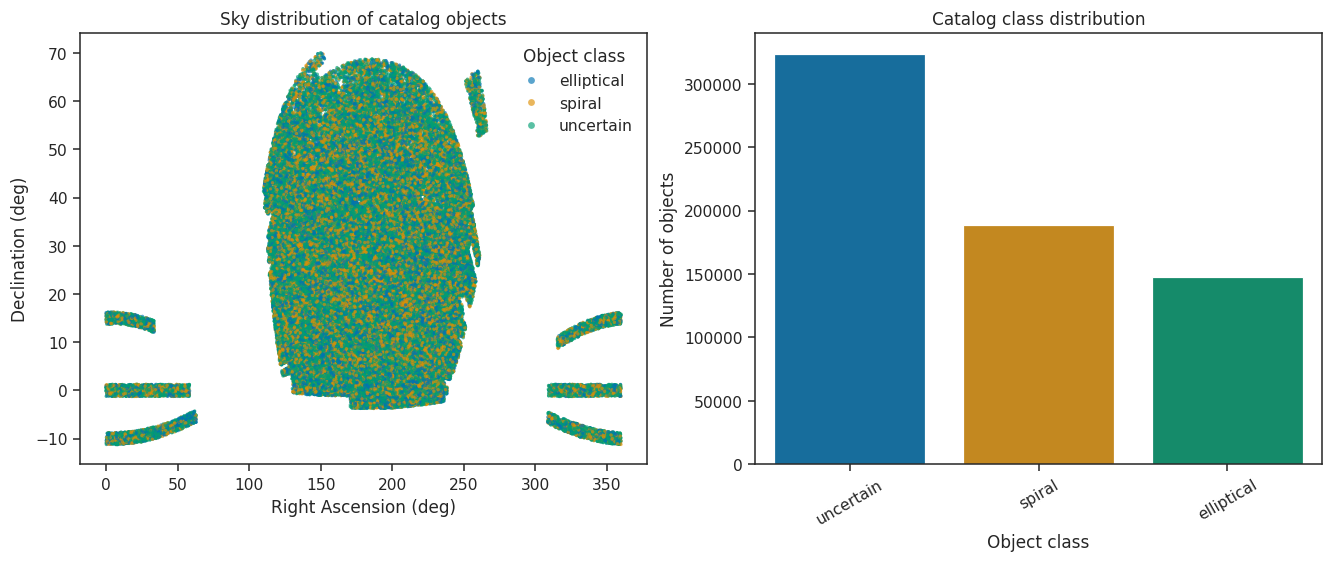

In [5]:
sns.set_theme(style="ticks", context="paper", font_scale=1.15)

plot_df = catalog if len(catalog) <= PLOT_MAX_POINTS else catalog.sample(PLOT_MAX_POINTS, random_state=SEED)
classes = sorted(catalog["class"].unique())
palette = sns.color_palette("colorblind", n_colors=len(classes))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

sns.scatterplot(data=plot_df, x="ra", y="dec", hue="class", hue_order=classes, palette=palette,
                s=5, alpha=0.65, linewidth=0, rasterized=True, ax=axes[0])
axes[0].set(xlabel="Right Ascension (deg)", ylabel="Declination (deg)",
            title="Sky distribution of catalog objects")
axes[0].legend(title="Object class", markerscale=2, frameon=False)

if "redshift" in catalog.columns:
    sns.histplot(data=plot_df.dropna(subset=["redshift"]), x="redshift", hue="class", hue_order=classes,
                 bins=50, element="step", stat="density", common_norm=False,
                 palette=palette, alpha=0.25, ax=axes[1])
    axes[1].set(xlabel="Redshift (z)", ylabel="Probability density", title="Redshift distribution by class")
else:
    counts = catalog["class"].value_counts()
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=palette, legend=False, ax=axes[1])
    axes[1].set(xlabel="Object class", ylabel="Number of objects", title="Catalog class distribution")
    axes[1].tick_params(axis="x", rotation=30)

fig.savefig(OUTPUT_DIR / "catalog_figure.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "catalog_figure.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Balanced sample of the classes to learn

Only the classes in `CLASSES` are kept (by default elliptical vs spiral, including the uncertain galaxies re-labelled in section 2; the rest are left out). Each class contributes at most `MAX_PER_CLASS` galaxies, so the training set is balanced.

In [6]:
unknown = [c for c in CLASSES if c not in set(catalog["class"])]
if unknown:
    raise ValueError(f"Classes {unknown} not found in the catalog. Available: {sorted(catalog['class'].unique())}")

pool = catalog[catalog["class"].isin(CLASSES)]
parts = []
for name in CLASSES:
    g = pool[pool["class"] == name]
    n = len(g) if MAX_PER_CLASS is None else min(len(g), MAX_PER_CLASS)
    parts.append(g.sample(n=n, random_state=SEED))

subset = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffled
class_to_id = {name: i for i, name in enumerate(CLASSES)}
subset["label_id"] = subset["class"].map(class_to_id)

print("Selected objects:", len(subset))
print(subset["class"].value_counts())
print("Class mapping:", class_to_id)

Selected objects: 50000
class
spiral        25000
elliptical    25000
Name: count, dtype: int64
Class mapping: {'elliptical': 0, 'spiral': 1}


## 5. Download the SDSS cutouts

Each galaxy gets a 64×64 RGB cutout from the SDSS SkyServer (`ImgCutout/getjpeg`), downloaded in parallel with retries.

The result is cached in `outputs/sdss_cutouts.npz`. If you re-run the notebook with the same CSV and settings, the cache is reused and only **failed** downloads are retried.

In [7]:
def download_cutout(idx, ra, dec):
    # Return (idx, image HxWx3 uint8, error). Image is None if all retries failed.
    params = {"ra": float(ra), "dec": float(dec), "scale": SCALE,
              "width": IMAGE_SIZE, "height": IMAGE_SIZE}
    for attempt in range(MAX_RETRIES):
        try:
            with requests.Session() as session:           # one session per call: thread safe
                r = session.get(BASE_URL, params=params, timeout=TIMEOUT)
                r.raise_for_status()
            img = Image.open(io.BytesIO(r.content)).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
            return idx, np.asarray(img), None
        except Exception as exc:
            if attempt == MAX_RETRIES - 1:
                return idx, None, str(exc)
            time.sleep(2 ** attempt)

In [ ]:
CACHE_FILE = OUTPUT_DIR / "sdss_cutouts.npz"
n = len(subset)
images = np.zeros((n, IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
ok = np.zeros(n, dtype=bool)

# ---- reuse the cache if it belongs to this exact sample ----
if USE_CACHE and CACHE_FILE.exists():
    c = np.load(CACHE_FILE)
    same = (len(c["ra"]) == n and int(c["image_size"]) == IMAGE_SIZE and float(c["scale"]) == SCALE
            and np.allclose(c["ra"], subset["ra"]) and np.allclose(c["dec"], subset["dec"]))
    if same:
        images, ok = c["images"].copy(), c["ok"].copy()
        print(f"Cache loaded: {ok.sum()} / {n} cutouts available")
    else:
        print("Cache found but it does not match this sample -> downloading again")

# ---- download what is missing ----
pending = np.flatnonzero(~ok)
errors = []
if len(pending):
    ra, dec = subset["ra"].to_numpy(), subset["dec"].to_numpy()
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool_:
        futures = [pool_.submit(download_cutout, i, ra[i], dec[i]) for i in pending]
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Downloading SDSS cutouts"):
            i, img, err = fut.result()
            if err is None:
                images[i], ok[i] = img, True
            else:
                errors.append({"index": i, "ra": ra[i], "dec": dec[i], "error": err})

    np.savez_compressed(CACHE_FILE, images=images, ok=ok, ra=subset["ra"].to_numpy(),
                        dec=subset["dec"].to_numpy(), labels=subset["label_id"].to_numpy(),
                        image_size=IMAGE_SIZE, scale=SCALE)
    print(f"Saved cache: {CACHE_FILE}")

pd.DataFrame(errors).to_csv(OUTPUT_DIR / "download_errors.csv", index=False)
subset.to_csv(OUTPUT_DIR / "cutout_metadata.csv", index=False)
print(f"Successful: {ok.sum()}   Failed: {(~ok).sum()}")
if ok.sum() == 0:
    raise RuntimeError("No cutout could be downloaded. Check your internet connection / BASE_URL.")

In [ ]:
# Visual check of random cutouts
rng = np.random.default_rng(SEED)
valid = np.flatnonzero(ok)
sample = rng.choice(valid, size=min(9, len(valid)), replace=False)

fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, i in zip(axes.flat, sample):
    ax.imshow(images[i]); ax.set_title(subset.loc[i, "class"]); ax.axis("off")
for ax in axes.flat[len(sample):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Stamps → features

Galaxies whose cutout failed are dropped, so catalog rows and images stay aligned. Each RGB stamp is converted to **grayscale**, scaled to [0, 1] and flattened into **64×64 = 4096** features.

In [ ]:
subset = subset[ok].reset_index(drop=True)
images = images[ok]

# Grayscale (ITU-R 601 luma, same as PIL's convert("L")) and flatten
gray = images.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
X_stamps = (gray / 255.0).reshape(len(images), -1)
print("Stamp matrix:", X_stamps.shape)        # (n_galaxies, 4096)

## 7. Merge catalog + stamp features into one feature table

**Automatic catalog feature selection** (when `CATALOG_FEATURES = None`): numeric columns, excluding

* the label columns (`class`, `spiral`, `elliptical`, `uncertain`, `label_id`)
* identifiers (`*objid`, `*id`) and, by default, `ra`/`dec`
* Galaxy Zoo vote columns (`p_*`, `nvote*`), which *are* the label in disguise
* constant / empty columns
* any column with |correlation| with the target above `LEAKAGE_CORR_THRESHOLD`

> Check the printed list: a feature that encodes the answer would give a misleadingly perfect score.

In [ ]:
y = subset["label_id"].to_numpy()

LABEL_COLS = {"class", "class_original", "spiral", "elliptical", "uncertain", "unknown", "label_id", "target"}
if CATALOG_FEATURES is None:
    cand = subset.select_dtypes(include="number").columns
    drop = set(LABEL_COLS)
    if not USE_COORDINATES:
        drop |= {"ra", "dec"}
    drop |= {c for c in cand if re.search(r"(^|_)(obj|specobj|dr\d+obj|spec|plate|mjd|fiber)?id$", c)}
    drop |= {c for c in cand if re.match(r"^(p_|nvote)", c)}
    excluded = [c for c in cand if c in drop]
    cand = [c for c in cand if c not in drop]
    print("  excluded by rule (labels / ids / coordinates / GZ votes):", excluded)

    keep, dropped = [], []
    target_s = pd.Series(y, index=subset.index)
    for c in cand:
        col = subset[c].replace([np.inf, -np.inf], np.nan)
        if col.notna().sum() < 0.5 * len(col) or col.nunique() < 2:
            dropped.append((c, "empty/constant")); continue
        r = col.corr(target_s)
        if pd.notna(r) and abs(r) > LEAKAGE_CORR_THRESHOLD:
            dropped.append((c, f"leakage? |corr|={abs(r):.2f}")); continue
        keep.append(c)
    CATALOG_FEATURES = keep
    for c, why in dropped:
        print(f"  dropped {c:25s} ({why})")
else:
    CATALOG_FEATURES = [c for c in CATALOG_FEATURES if c in subset.columns]

print(f"\n{len(CATALOG_FEATURES)} catalog features used:", CATALOG_FEATURES)

PIXEL_COLS = [f"px_{k:04d}" for k in range(X_stamps.shape[1])]
stamp_df = pd.DataFrame(X_stamps, columns=PIXEL_COLS)
cat_df = subset[CATALOG_FEATURES].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
X = pd.concat([cat_df, stamp_df], axis=1)

print("Feature table:", X.shape, "| target:", y.shape, "| spiral fraction: %.3f" % y.mean())

## 8. Train / test split

A **stratified** split keeps the class proportions in both sets. The test set is not touched until the final evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

## 9. Model pipeline (scikit-learn)

* **Stamp features** → `PCA(64)` → standardisation
* **Catalog features** → median imputation → standardisation
* Both blocks concatenated → **SVC** (RBF kernel, `class_weight="balanced"`)

PCA and scalers live **inside** the `Pipeline`, so they are fitted on the training data only (no test-set leakage). If there are no catalog features, the model uses the stamps only.

In [ ]:
def make_model(classifier, use_catalog=True, use_stamps=True, n_pca=N_PCA):
    blocks = []
    if use_catalog and CATALOG_FEATURES:
        blocks.append(("catalog",
                       Pipeline([("imputer", SimpleImputer(strategy="median")),
                                 ("scaler", StandardScaler())]),
                       CATALOG_FEATURES))
    if use_stamps:
        blocks.append(("stamps",
                       Pipeline([("pca", PCA(n_components=n_pca, random_state=SEED)),
                                 ("scaler", StandardScaler())]),
                       PIXEL_COLS))
    return Pipeline([("pre", ColumnTransformer(blocks)), ("clf", classifier)])

HAS_CATALOG = len(CATALOG_FEATURES) > 0

svc = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
          probability=True, random_state=SEED)
model = make_model(svc)
model.fit(X_train, y_train)
print("Training done.")

## 10. Evaluation on the test set

In [ ]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASSES, cmap="Blues", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[0].set_title("Confusion matrix"); axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

## 11. What does each source of information contribute?

Catalog only vs stamps only vs both, with 5-fold cross-validation on the training set.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

variants = {"stamps only": dict(use_catalog=False)}
if HAS_CATALOG:
    variants = {"catalog only": dict(use_stamps=False), **variants, "catalog + stamps": dict()}

results = {}
for name, kw in variants.items():
    clf = SVC(kernel="rbf", class_weight="balanced", random_state=SEED)
    s = cross_val_score(make_model(clf, **kw), X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    results[name] = (s.mean(), s.std())
    print(f"{name:18s} accuracy = {s.mean():.3f} ± {s.std():.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(results.keys(), [v[0] for v in results.values()], yerr=[v[1] for v in results.values()], capsize=4)
ax.set_ylabel("CV accuracy"); ax.set_ylim(0.5, 1.0)
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 12. How many PCA components do we need?

In [ ]:
n_comp = min(200, len(X_train) - 1, len(PIXEL_COLS))
pca_full = PCA(n_components=n_comp, random_state=SEED).fit(X_train[PIXEL_COLS])
cum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cum) + 1), cum)
plt.axvline(N_PCA, color="r", ls="--", label=f"{N_PCA} components: {cum[N_PCA-1]:.1%}")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for k, ax in enumerate(axes):
    ax.imshow(pca_full.components_[k].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray"); ax.axis("off")
    ax.set_title(f"PC{k+1}", fontsize=9)
plt.tight_layout(); plt.show()

## 13. Hyperparameter tuning (SVC)

Small grid search with cross-validation, on the training set only.

In [ ]:
param_grid = {
    "pre__stamps__pca__n_components": [16, 32, 64],
    "clf__C": [0.5, 1, 5, 20],
    "clf__gamma": ["scale", 0.01],
}
search = GridSearchCV(
    make_model(SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED)),
    param_grid, cv=cv, scoring="accuracy", n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.3f}")

## 14. Comparison with other algorithms

In [ ]:
candidates = {
    "SVC (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=SEED, n_jobs=-1),
}
for name, clf in candidates.items():
    s = cross_val_score(make_model(clf), X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    print(f"{name:20s} CV accuracy = {s.mean():.3f} ± {s.std():.3f}")

## 15. Final model on the test set

The best model of the grid search (already refitted on the whole training set) is evaluated **once** on the test set.

In [ ]:
best = search.best_estimator_
y_pred  = best.predict(X_test)
y_proba = best.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test ROC AUC : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=CLASSES))

# Misclassified galaxies (original colour cutouts)
wrong = np.where(y_pred != y_test)[0]
test_idx = X_test.index.to_numpy()
m = min(10, len(wrong))
if m:
    fig, axes = plt.subplots(1, m, figsize=(1.8 * m, 2.4), squeeze=False)
    for ax, w in zip(axes[0], wrong[:m]):
        ax.imshow(images[test_idx[w]]); ax.axis("off")
        ax.set_title(f"true: {CLASSES[y_test[w]][:4]}\npred: {CLASSES[y_pred[w]][:4]}", fontsize=8)
    plt.tight_layout(); plt.show()

## 16. Save the model and the test predictions

In [ ]:
joblib.dump({"model": best, "classes": CLASSES, "catalog_features": CATALOG_FEATURES,
             "pixel_cols": PIXEL_COLS, "image_size": IMAGE_SIZE},
            OUTPUT_DIR / "galaxy_morphology_model.joblib")

pred_df = subset.loc[X_test.index, ["ra", "dec", "class"]].copy()
pred_df["predicted"] = [CLASSES[k] for k in y_pred]
pred_df["p_" + CLASSES[1]] = y_proba
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

print("Saved in", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

# To reuse the model later:
#   bundle = joblib.load("outputs/galaxy_morphology_model.joblib")
#   bundle["model"].predict(new_feature_table)   # same columns as X

## 17. Notes for the final presentation

* Which source of information was more useful: catalog, stamps, or both? (section 11)
* How much variance do 64 PCA components keep? (section 12)
* Best hyperparameters and final test accuracy / AUC (sections 13 and 15).
* Typical failure cases (edge-on spirals that look elliptical, faint or small galaxies).
* **Ideas to improve:** data augmentation (rotations/flips), colour information (3 channels instead of grayscale), a CNN, extra catalog features (colours such as `g-r`, concentration `R90/R50`), larger `MAX_PER_CLASS`.